<a href="https://colab.research.google.com/github/minhphu12-oc/basic-python/blob/sklearn-project-for-machine-learning/project_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bước 1 : Phân tích dữ liệu

In [2]:
import pandas as pd
df = pd.read_csv("UNSW_NB15_training-set.csv")

In [3]:
# đọc 5 dòng đầu của dữ liệu
df.head(5)

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [4]:
df.shape

(175341, 45)

In [5]:
# đọc thông tin dữ liệu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

In [6]:
# tìm giá trị thiếu
df.isnull().sum()

,0
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0


In [7]:
# đọc trạng thái
df.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [8]:
# xem phân bổ dữ liệu
df['label'].value_counts()

,count
label,
1,119341
0,56000


In [9]:
df['attack_cat'].value_counts()

,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


In [10]:
df['service'].value_counts()

,count
service,
-,94168
dns,47294
http,18724
smtp,5058
ftp-data,3995
ftp,3428
ssh,1302
pop3,1105
dhcp,94


In [11]:
df['is_ftp_login'].value_counts()

,count
is_ftp_login,
0,172774
1,2545
4,16
2,6


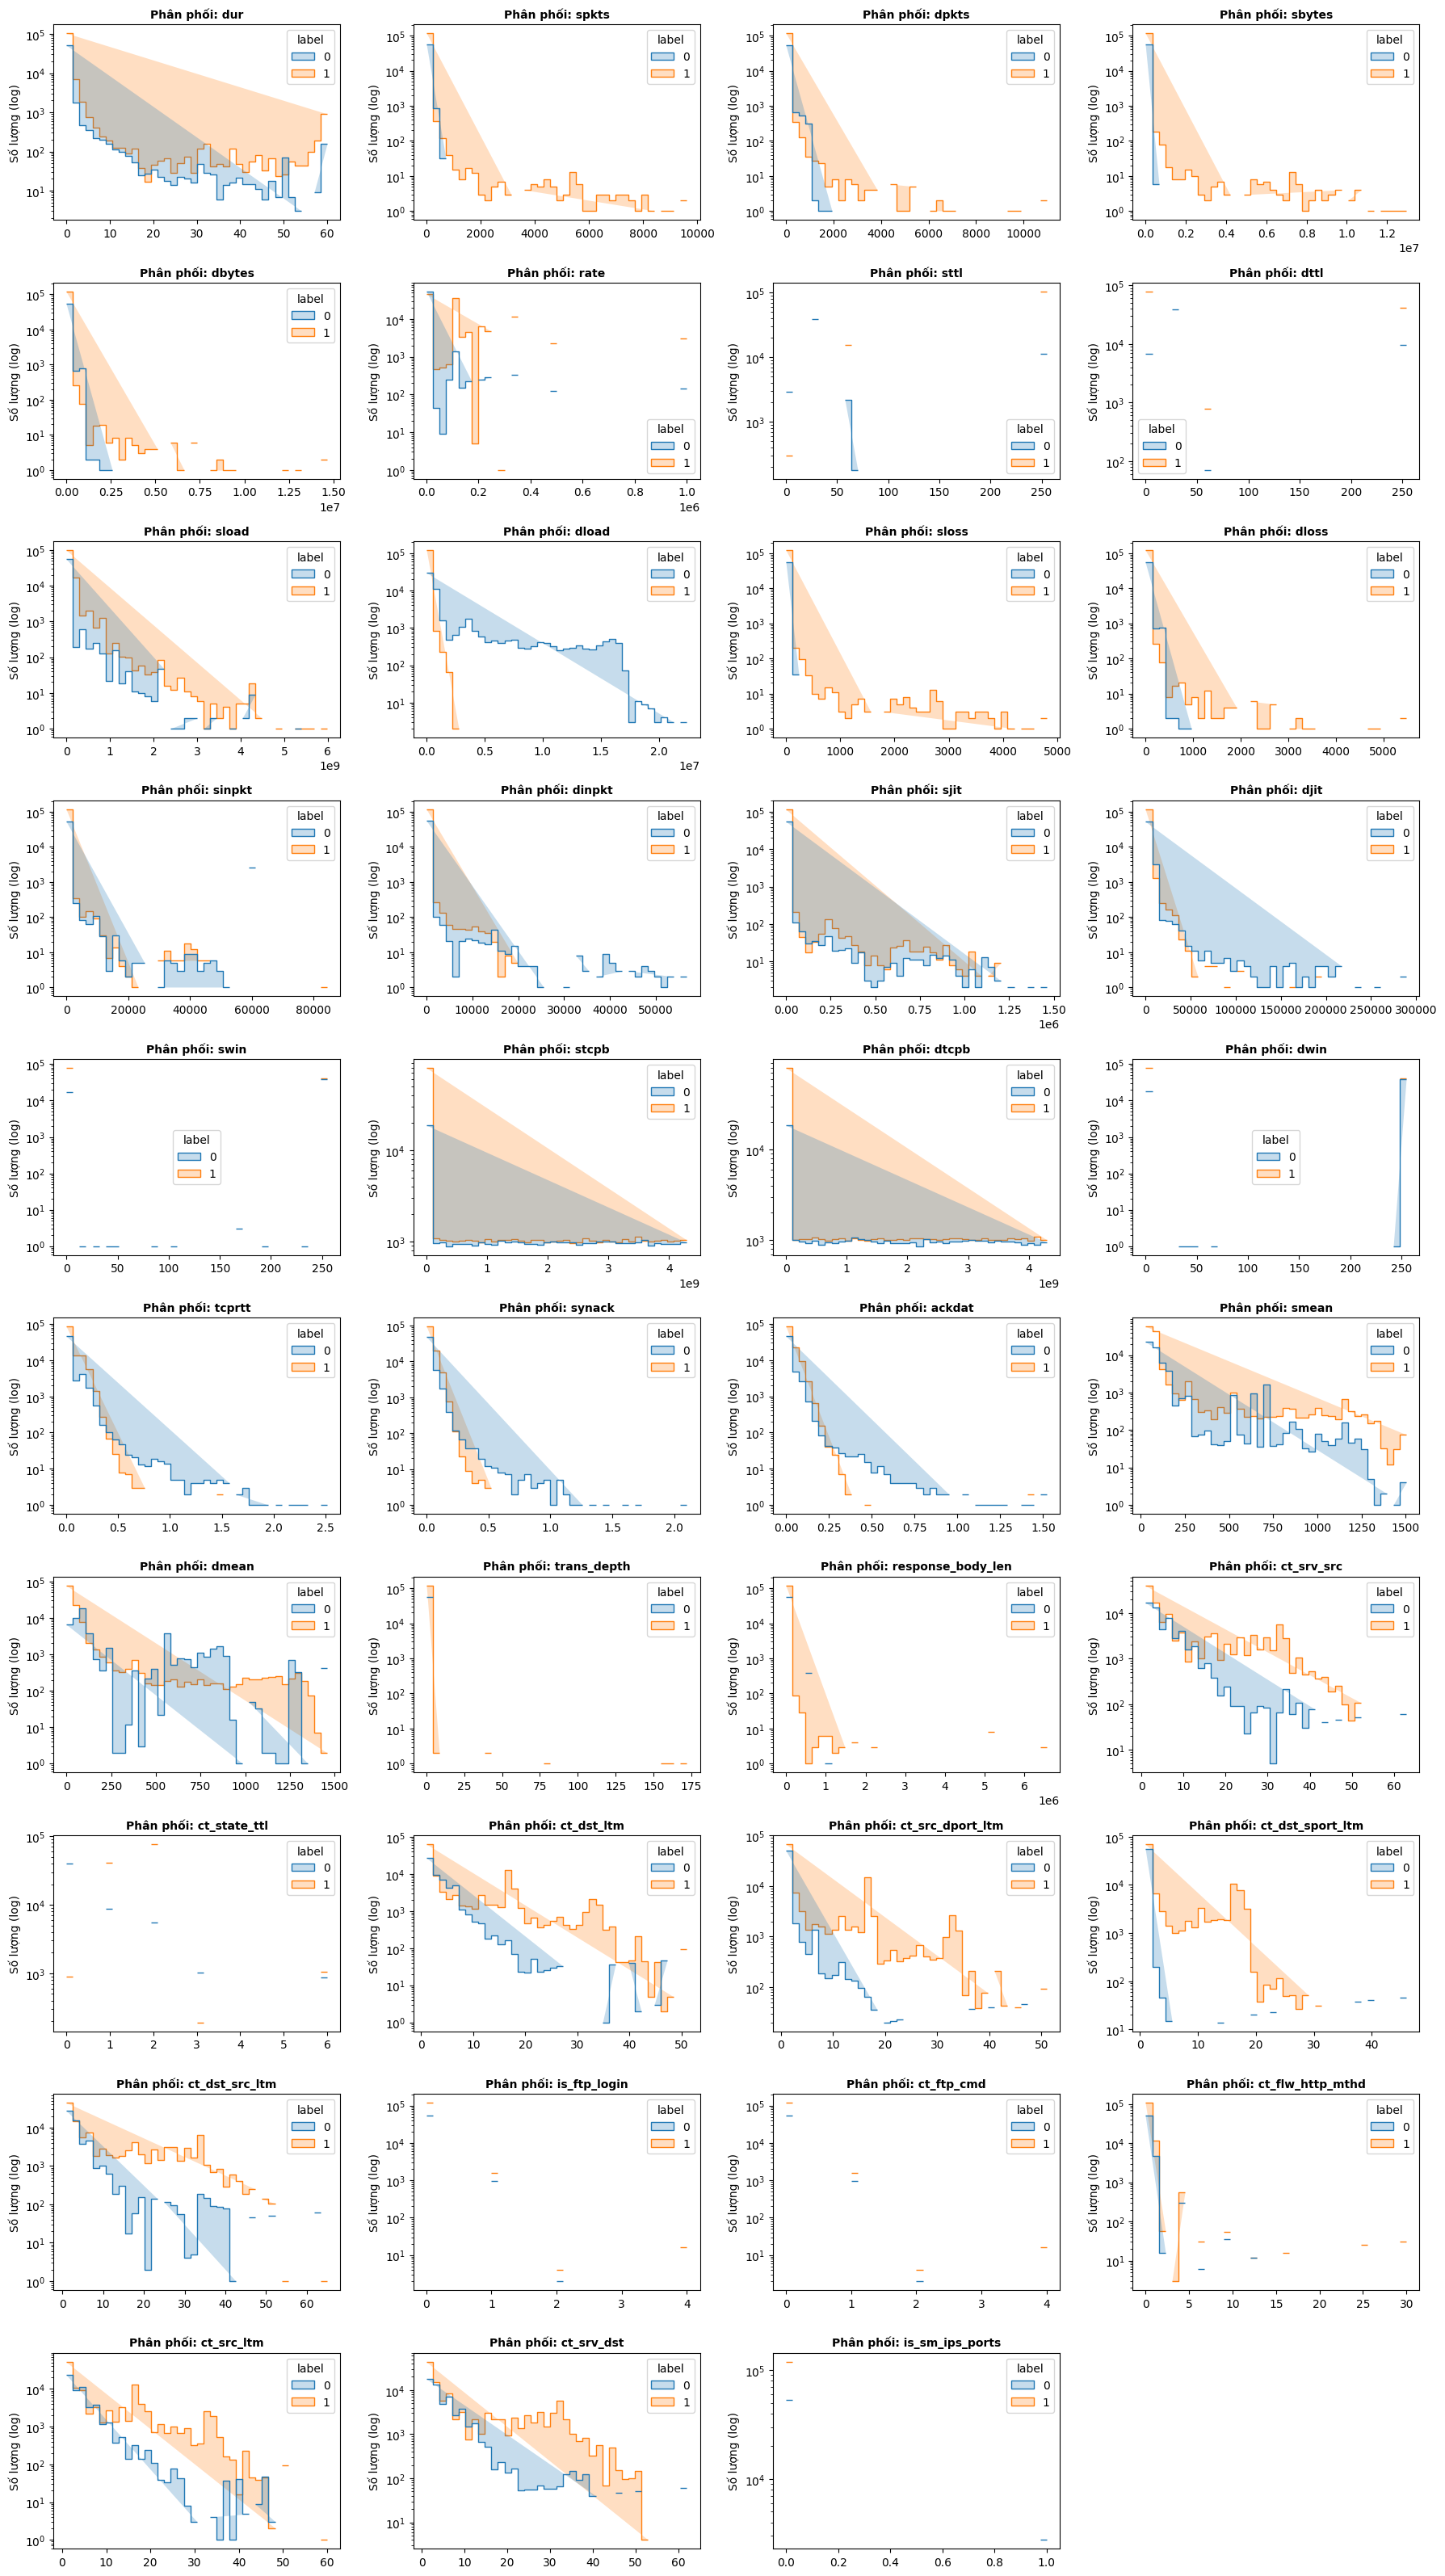

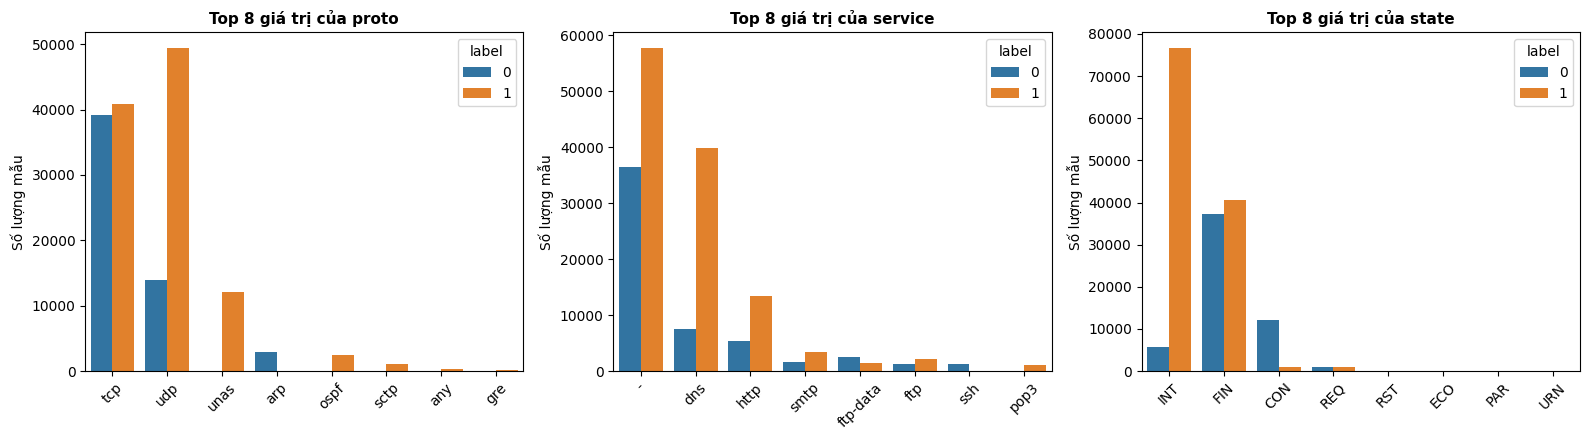

In [12]:
# vẽ sự tương quan, độ lệch giữa các feature

import math
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

num_cols = df.select_dtypes(include=[np.number]).drop(columns=['id', 'label']).columns

n_cols = 4
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.2))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        data=df,
        x=col,
        hue='label',
        bins=40,
        ax=axes[i],
        log_scale=(False, True),
        element='step',
        palette={0: '#1f77b4', 1: '#ff7f0e'}
    )
    axes[i].set_title(f'Phân phối: {col}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng (log)')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

cat_cols = ['proto', 'service', 'state']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(cat_cols):
    top_vals = df[col].value_counts().head(8).index
    sns.countplot(
        data=df[df[col].isin(top_vals)],
        x=col,
        hue='label',
        order=top_vals,
        ax=axes[i],
        palette={0: '#1f77b4', 1: '#ff7f0e'}
    )
    axes[i].set_title(f'Top 8 giá trị của {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng mẫu')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

0 : an toàn

1 : tấn công

# Bước 2 : Xử lí dữ liệu

In [13]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = df.dropna(subset=['label'])

df = df.drop(columns=['id', 'attack_cat'], errors='ignore')

# Chuẩn hóa cờ nhị phân is_ftp_login (đưa giá trị > 0 về 1)
df['is_ftp_login'] = (df['is_ftp_login'] > 0).astype(int)

# Đổi ký tự '-' trong service thành 'unknown'
df['service'] = df['service'].replace('-', 'unknown')

# Loại bỏ các cột đa cộng tuyến mạnh (r > 0.96)
collinear_cols = ['ct_ftp_cmd', 'sloss', 'dloss', 'dwin', 'ct_srv_dst', 'ct_dst_src_ltm']
df = df.drop(columns=collinear_cols, errors='ignore')

# Gom nhóm các nhãn phân loại hiếm (< 100 mẫu) thành 'other'
for col in ['proto', 'service', 'state']:
    counts = df[col].value_counts()
    rare_labels = counts[counts < 100].index
    df[col] = df[col].replace(rare_labels, 'other')

x = df.drop(columns=['label'])
y = df['label']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

cat_cols = ['proto', 'service', 'state']
num_cols = x_train.select_dtypes(include=[np.number]).columns.tolist()

exclude_cols = ['is_ftp_login', 'is_sm_ips_ports']
num_cols = [col for col in num_cols if col not in exclude_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

x_train = preprocessor.fit_transform(x_train)
x_test = preprocessor.transform(x_test)

In [14]:
print(x_train.shape)
print(x_test.shape)

(140272, 148)
(35069, 148)


# 10 Mô hình :
1. logistic regression
2. bayes
3. svm
4. decision tree
5. xgboost
6. sgd
7. CNN
8. MLP
9. KNN
10. Tabnet

In [15]:
!pip install pytorch-tabnet

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import SGDClassifier
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif

# Bước 3 : Train model

3.1 Feature selection

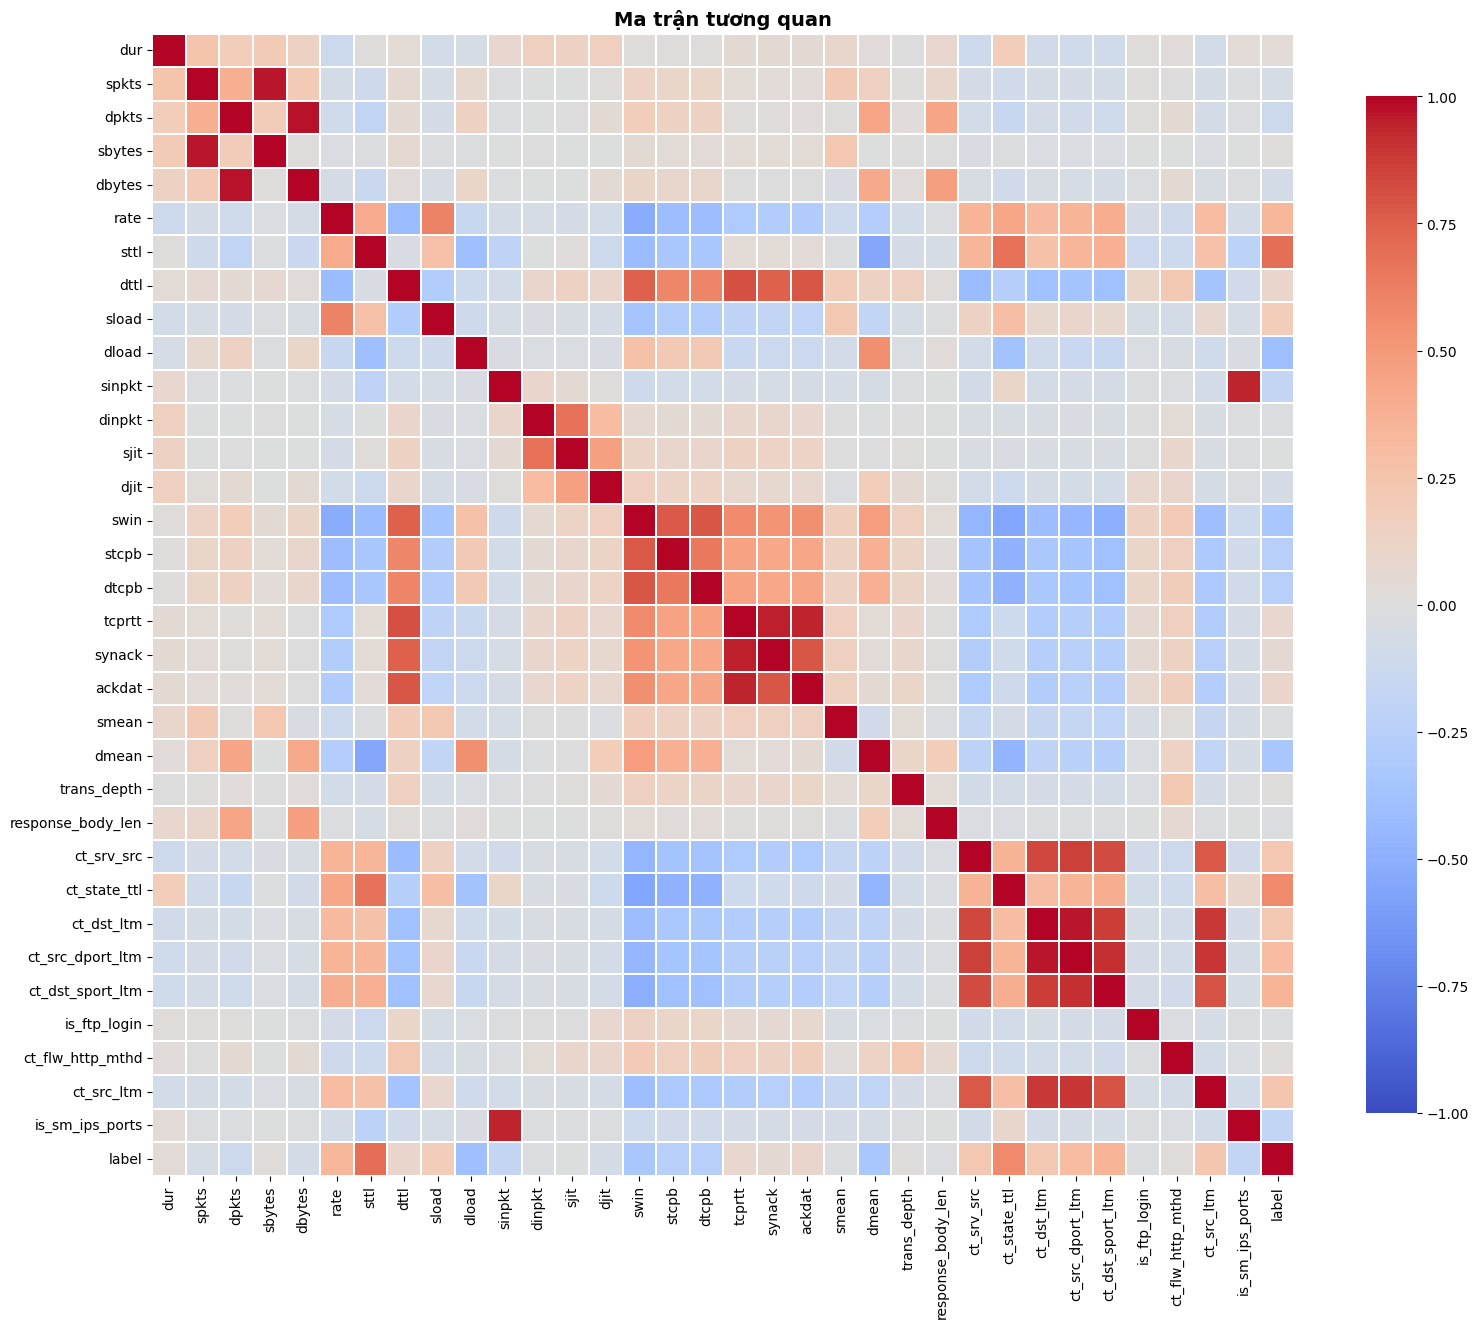

In [16]:
# vẽ ma trận tương quan
corr = df.corr(numeric_only=True)
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={'shrink': 0.8}
)
plt.title('Ma trận tương quan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

3.1.1 Logistic Regression

In [17]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', LogisticRegression(max_iter = 3000, tol = 1e-3))
])
param_grid = [{
        'select__k': [4, 8, 16],
        'model__C': [0.01, 0.1, 1, 10]}]
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_log = GridSearchCV(pipeline, param_grid, cv=st, scoring='f1')
grid_log.fit(x_train, y_train)
predict = grid_log.predict(x_test)

Accuracy: 0.9191023410989763
Precision: 0.8980619274736922
Recall: 0.9939670702584943
F1 score: 0.9435838288225585
Best param {'model__C': 1, 'select__k': 16}


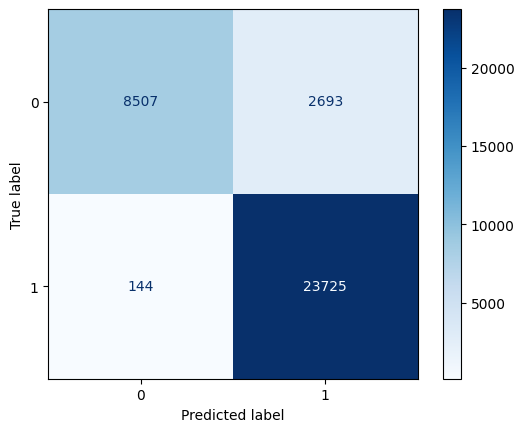

In [18]:
print("Accuracy:", accuracy_score(y_test, predict))
print("Precision:", precision_score(y_test, predict))
print("Recall:", recall_score(y_test, predict))
print("F1 score:", f1_score(y_test, predict))
print("Best param", grid_log.best_params_)
con = confusion_matrix(y_test, predict)
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=grid_log.classes_)
disp.plot(cmap=plt.cm.Blues)

In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import time
import numpy as np
best_params = grid_log.best_params_
print("Best params:", best_params)

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(
    grid_log.best_estimator_, x_train, y_train, cv=st, method='predict_proba', n_jobs=-1
)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1_scores = [f1_score(y_train, (oof_probs >= t).astype(int)) for t in thresholds]

best_idx = np.argmax(oof_f1_scores)
best_thresh = round(float(thresholds[best_idx]), 2)
print(f"Best Threshold (OOF Train): {best_thresh} | Best OOF F1: {oof_f1_scores[best_idx]:.4f}")

k_list = [4, 8, 16]
rows = []

for k in k_list:
    pipe_k = clone(grid_log.best_estimator_)
    pipe_k.set_params(select__k=k)

    t0 = time.time()
    pipe_k.fit(x_train, y_train)
    train_time = time.time() - t0

    t1 = time.time()
    test_probs = pipe_k.predict_proba(x_test)[:, 1]
    y_pred = (test_probs >= best_thresh).astype(int)
    infer_time_ms = (time.time() - t1) * 1000

    rows.append({
        'So_Dac_Trung_k': k,
        'Best_Threshold': best_thresh,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1_Score': round(f1_score(y_test, y_pred), 4),
        'Train_Time_s': round(train_time, 4),
        'Infer_Time_ms': round(infer_time_ms, 2)
    })

best_k_table = pd.DataFrame(rows)
print(best_k_table.to_string(index=False))

Best params: {'model__C': 1, 'select__k': 16}
Best Threshold (OOF Train): 0.56 | Best OOF F1: 0.9458
 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score  Train_Time_s  Infer_Time_ms
              4            0.56    0.8281     0.8749  0.8721    0.8735        0.4043          13.37
              8            0.56    0.8695     0.9007  0.9083    0.9045        0.4815           8.60
             16            0.56    0.9295     0.9133  0.9904    0.9503        1.1894          20.50


3.1.2 Bayes

In [20]:
pipeline = Pipeline(
    [('select', SelectKBest(f_classif)), ('model', GaussianNB())]
)

param_grid = [
    {'select__k': [4, 8, 16],
     'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}
]

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_nb = GridSearchCV(pipeline, param_grid, cv=st, scoring='f1')
grid_nb.fit(x_train, y_train)
predict = grid_nb.predict(x_test)

Accuracy: 0.8871082722632524
Precision: 0.8820323892854401
Recall: 0.9629226192969961
F1 score: 0.9207042281731328
Best param {'model__var_smoothing': 1e-09, 'select__k': 4}


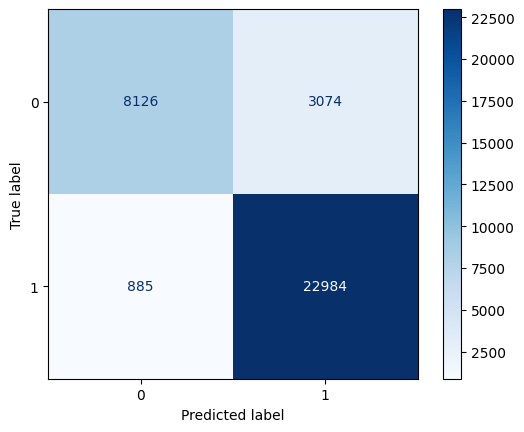

In [21]:
print("Accuracy:", accuracy_score(y_test, predict))
print("Precision:", precision_score(y_test, predict))
print("Recall:", recall_score(y_test, predict))
print("F1 score:", f1_score(y_test, predict))
print("Best param", grid_nb.best_params_)
con = confusion_matrix(y_test, predict)
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=grid_nb.classes_)
disp.plot(cmap=plt.cm.Blues)

In [22]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

best_params = grid_nb.best_params_
print("Best params:", best_params)

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(
    grid_nb.best_estimator_,
    x_train,
    y_train,
    cv=st,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1_scores = [
    f1_score(y_train, (oof_probs >= t).astype(int)) for t in thresholds
]

best_idx = np.argmax(oof_f1_scores)
best_thresh = round(float(thresholds[best_idx]), 2)
print(
    f"Best Threshold (OOF Train): {best_thresh} | Best OOF F1:"
    f" {oof_f1_scores[best_idx]:.4f}"
)

k_list = [4, 8, 16]
rows = []

for k in k_list:
  pipe_k = clone(grid_nb.best_estimator_)
  pipe_k.set_params(select__k=k)

  t0 = time.time()
  pipe_k.fit(x_train, y_train)
  train_time = time.time() - t0

  t1 = time.time()
  test_probs = pipe_k.predict_proba(x_test)[:, 1]
  y_pred = (test_probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000

  rows.append({
      "So_Dac_Trung_k": k,
      "Best_Threshold": best_thresh,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1_Score": round(f1_score(y_test, y_pred), 4),
      "Train_Time_s": round(train_time, 4),
      "Infer_Time_ms": round(infer_time_ms, 2),
  })

best_k_table = pd.DataFrame(rows)
print(best_k_table.to_string(index=False))

Best params: {'model__var_smoothing': 1e-09, 'select__k': 4}
Best Threshold (OOF Train): 0.1 | Best OOF F1: 0.9257
 So_Dac_Trung_k  Best_Threshold  Accuracy  Precision  Recall  F1_Score  Train_Time_s  Infer_Time_ms
              4             0.1    0.8959     0.8789  0.9824    0.9278        0.2567           9.60
              8             0.1    0.8802     0.8832  0.9497    0.9152        0.2738          11.34
             16             0.1    0.8070     0.8877  0.8202    0.8526        0.2798          15.37


3.1.3 KNN

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', KNeighborsClassifier(n_jobs=-1)),
])

param_grid = [{
    'select__k': [4, 8, 16],
    'model__n_neighbors': [3, 5, 7, 11],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
}]

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_knn = GridSearchCV(pipeline, param_grid, cv=st, scoring='f1', n_jobs=-1)
grid_knn.fit(x_train, y_train)
predict = grid_knn.predict(x_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, predict))
print("Precision:", precision_score(y_test, predict))
print("Recall:", recall_score(y_test, predict))
print("F1 score:", f1_score(y_test, predict))
print("Best param", grid_nb.best_params_)
con = confusion_matrix(y_test, predict)
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=grid_nb.classes_)
disp.plot(cmap=plt.cm.Blues)

In [ ]:
best_params = grid_knn.best_params_
print("Best params:", best_params)

k_list = [4, 8, 16]
rows = []

for k in k_list:
  pipe_k = clone(grid_knn.best_estimator_)
  pipe_k.set_params(select__k=k)

  t0 = time.time()
  pipe_k.fit(x_train, y_train)
  train_time = time.time() - t0

  t1 = time.time()
  y_pred = pipe_k.predict(x_test)
  infer_time_ms = (time.time() - t1) * 1000

  rows.append({
      "So_Dac_Trung_k": k,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1_Score": round(f1_score(y_test, y_pred), 4),
      "Train_Time_s": round(train_time, 4),
      "Infer_Time_ms": round(infer_time_ms, 2),
  })

best_k_table = pd.DataFrame(rows)
print(best_k_table.to_string(index=False))

3.1.4 SVM

In [ ]:
pipeline = Pipeline(
    [('select', SelectKBest(f_classif)), ('model', SVC(random_state=42))]
)

param_grid = [{
    'select__k': [4, 8, 16],
    'model__kernel': ['linear', 'rbf', 'poly'],
    'model__C': [0.1, 1, 10],
    'model__gamma': ['scale', 'auto', 0.01, 0.1],
    'model__degree': [2, 3],
    'model__class_weight': [None, 'balanced'],
}]

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_svm = GridSearchCV(pipeline, param_grid, cv=st, scoring='f1', n_jobs=-1)
grid_svm.fit(x_train, y_train)
predict = grid_svm.predict(x_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, predict))
print("Precision:", precision_score(y_test, predict))
print("Recall:", recall_score(y_test, predict))
print("F1 score:", f1_score(y_test, predict))
print("Best param", grid_nb.best_params_)
con = confusion_matrix(y_test, predict)
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=grid_nb.classes_)
disp.plot(cmap=plt.cm.Blues)

In [ ]:
best_params = grid_svm.best_params_
print("Best params:", best_params)

k_list = [4, 8, 16]
rows = []

for k in k_list:
  pipe_k = clone(grid_svm.best_estimator_)
  pipe_k.set_params(select__k=k)

  t0 = time.time()
  pipe_k.fit(x_train, y_train)
  train_time = time.time() - t0

  t1 = time.time()
  y_pred = pipe_k.predict(x_test)
  infer_time_ms = (time.time() - t1) * 1000

  rows.append({
      "So_Dac_Trung_k": k,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1_Score": round(f1_score(y_test, y_pred), 4),
      "Train_Time_s": round(train_time, 4),
      "Infer_Time_ms": round(infer_time_ms, 2),
  })

best_k_table = pd.DataFrame(rows)
print(best_k_table.to_string(index=False))

3.1.5 DecisionTree

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', DecisionTreeClassifier(random_state=42)),
])

param_grid = [{
    'select__k': [4, 8, 16],
    'model__criterion': ['gini', 'entropy'],
    'model__splitter': ['best', 'random'],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': [None, 'balanced'],
}]

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_dt = GridSearchCV(pipeline, param_grid, cv=st, scoring='f1', n_jobs=-1)
grid_dt.fit(x_train, y_train)
predict = grid_dt.predict(x_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, predict))
print("Precision:", precision_score(y_test, predict))
print("Recall:", recall_score(y_test, predict))
print("F1 score:", f1_score(y_test, predict))
print("Best param", grid_nb.best_params_)
con = confusion_matrix(y_test, predict)
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=grid_nb.classes_)
disp.plot(cmap=plt.cm.Blues)

In [ ]:
best_params = grid_dt.best_params_
print("Best params:", best_params)

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(
    grid_dt.best_estimator_,
    x_train,
    y_train,
    cv=st,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1_scores = [
    f1_score(y_train, (oof_probs >= t).astype(int)) for t in thresholds
]

best_idx = np.argmax(oof_f1_scores)
best_thresh = round(float(thresholds[best_idx]), 2)
print(
    f"Best Threshold (OOF Train): {best_thresh} | Best OOF F1:"
    f" {oof_f1_scores[best_idx]:.4f}"
)

k_list = [4, 8, 16]
rows = []

for k in k_list:
  pipe_k = clone(grid_dt.best_estimator_)
  pipe_k.set_params(select__k=k)

  t0 = time.time()
  pipe_k.fit(x_train, y_train)
  train_time = time.time() - t0

  t1 = time.time()
  test_probs = pipe_k.predict_proba(x_test)[:, 1]
  y_pred = (test_probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000

  rows.append({
      "So_Dac_Trung_k": k,
      "Best_Threshold": best_thresh,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1_Score": round(f1_score(y_test, y_pred), 4),
      "Train_Time_s": round(train_time, 4),
      "Infer_Time_ms": round(infer_time_ms, 2),
  })

best_k_table = pd.DataFrame(rows)
print(best_k_table.to_string(index=False))

3.1.6 XGB

In [ ]:
pipeline = Pipeline([
    ('select', SelectKBest(f_classif)),
    ('model', XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)),
])

param_grid = [{
    'select__k': [4, 8, 16],
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__scale_pos_weight': [1, 5],
}]

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_xgb = GridSearchCV(pipeline, param_grid, cv=st, scoring='f1', n_jobs=-1)
grid_xgb.fit(x_train, y_train)
predict = grid_xgb.predict(x_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, predict))
print("Precision:", precision_score(y_test, predict))
print("Recall:", recall_score(y_test, predict))
print("F1 score:", f1_score(y_test, predict))
print("Best param", grid_nb.best_params_)
con = confusion_matrix(y_test, predict)
disp = ConfusionMatrixDisplay(confusion_matrix=con, display_labels=grid_nb.classes_)
disp.plot(cmap=plt.cm.Blues)

In [ ]:
best_params = grid_xgb.best_params_
print("Best params:", best_params)

st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(
    grid_xgb.best_estimator_,
    x_train,
    y_train,
    cv=st,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1_scores = [
    f1_score(y_train, (oof_probs >= t).astype(int)) for t in thresholds
]

best_idx = np.argmax(oof_f1_scores)
best_thresh = round(float(thresholds[best_idx]), 2)
print(
    f"Best Threshold (OOF Train): {best_thresh} | Best OOF F1:"
    f" {oof_f1_scores[best_idx]:.4f}"
)

k_list = [4, 8, 16]
rows = []

for k in k_list:
  pipe_k = clone(grid_xgb.best_estimator_)
  pipe_k.set_params(select__k=k)

  t0 = time.time()
  pipe_k.fit(x_train, y_train)
  train_time = time.time() - t0

  t1 = time.time()
  test_probs = pipe_k.predict_proba(x_test)[:, 1]
  y_pred = (test_probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000

  rows.append({
      "So_Dac_Trung_k": k,
      "Best_Threshold": best_thresh,
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1_Score": round(f1_score(y_test, y_pred), 4),
      "Train_Time_s": round(train_time, 4),
      "Infer_Time_ms": round(infer_time_ms, 2),
  })

best_k_table = pd.DataFrame(rows)
print(best_k_table.to_string(index=False))

3.1.7 SGD

In [ ]:
class TorchSGD(nn.Module):
  def __init__(self, in_f, drop=0.1):
    super().__init__()
    self.norm = nn.LayerNorm(in_f)
    self.drop = nn.Dropout(drop)
    self.fc = nn.Linear(in_f, 1)
    nn.init.xavier_uniform_(self.fc.weight)
    nn.init.zeros_(self.fc.bias)
  def forward(self, x):
    x = self.norm(x)
    x = self.drop(x)
    return self.fc(x)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
param_grid = {'k': [4, 8, 16], 'lr': [1e-2, 1e-3, 1e-4], 'weight_decay': [1e-4, 1e-2], 'epochs': [15, 25]}
combos = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_f1, best_params = -1, None
for p in combos:
  oof = np.zeros(len(y_train))
  for tr_idx, va_idx in st.split(x_train, y_train):
    sel = SelectKBest(f_classif, k=p['k'])
    X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx])
    X_va = sel.transform(np.asarray(x_train)[va_idx])
    y_tr = np.asarray(y_train)[tr_idx]
    net = TorchSGD(X_tr.shape[1]).to(device)
    opt = torch.optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=p['weight_decay'])
    crit = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=256, shuffle=True)
    net.train()
    for _ in range(p['epochs']):
      for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        opt.zero_grad()
        loss = crit(net(bx).squeeze(-1), by)
        loss.backward()
        opt.step()
    net.eval()
    with torch.no_grad():
      oof[va_idx] = torch.sigmoid(net(torch.tensor(X_va, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
  score = f1_score(y_train, (oof >= 0.5).astype(int))
  if score > best_f1:
    best_f1, best_params = score, p

In [ ]:
print('Best params:', best_params)
oof = np.zeros(len(y_train))
for tr_idx, va_idx in st.split(x_train, y_train):
  sel = SelectKBest(f_classif, k=best_params['k'])
  X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx])
  X_va = sel.transform(np.asarray(x_train)[va_idx])
  y_tr = np.asarray(y_train)[tr_idx]
  net = TorchSGD(X_tr.shape[1]).to(device)
  opt = torch.optim.SGD(net.parameters(), lr=best_params['lr'], momentum=0.9, weight_decay=best_params['weight_decay'])
  crit = nn.BCEWithLogitsLoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=256, shuffle=True)
  net.train()
  for _ in range(best_params['epochs']):
    for bx, by in loader:
      bx, by = bx.to(device), by.to(device)
      opt.zero_grad()
      loss = crit(net(bx).squeeze(-1), by)
      loss.backward()
      opt.step()
  net.eval()
  with torch.no_grad():
    oof[va_idx] = torch.sigmoid(net(torch.tensor(X_va, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int)) for t in thresholds]
best_idx = np.argmax(oof_f1)
best_thresh = round(float(thresholds[best_idx]), 2)
print(f'Best Threshold (OOF Train): {best_thresh} | Best OOF F1: {oof_f1[best_idx]:.4f}')
rows = []
for k in [4, 8, 16]:
  t0 = time.time()
  sel = SelectKBest(f_classif, k=k)
  X_tr = sel.fit_transform(np.asarray(x_train), np.asarray(y_train))
  X_te = sel.transform(np.asarray(x_test))
  net = TorchSGD(X_tr.shape[1]).to(device)
  opt = torch.optim.SGD(net.parameters(), lr=best_params['lr'], momentum=0.9, weight_decay=best_params['weight_decay'])
  crit = nn.BCEWithLogitsLoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(np.asarray(y_train), dtype=torch.float32)), batch_size=256, shuffle=True)
  net.train()
  for _ in range(best_params['epochs']):
    for bx, by in loader:
      bx, by = bx.to(device), by.to(device)
      opt.zero_grad()
      loss = crit(net(bx).squeeze(-1), by)
      loss.backward()
      opt.step()
  train_time = time.time() - t0
  t1 = time.time()
  net.eval()
  with torch.no_grad():
    probs = torch.sigmoid(net(torch.tensor(X_te, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
  y_pred = (probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000
  rows.append({'So_Dac_Trung_k': k, 'Best_Threshold': best_thresh, 'Accuracy': round(accuracy_score(y_test, y_pred), 4), 'Precision': round(precision_score(y_test, y_pred), 4), 'Recall': round(recall_score(y_test, y_pred), 4), 'F1_Score': round(f1_score(y_test, y_pred), 4), 'Train_Time_s': round(train_time, 4), 'Infer_Time_ms': round(infer_time_ms, 2)})
print(pd.DataFrame(rows).to_string(index=False))

3.1.8 MLP

In [ ]:
class TorchMLP(nn.Module):
  def __init__(self, in_f, h1=128, h2=64, h3=32, drop=0.2):
    super().__init__()
    self.block1 = nn.Sequential(nn.Linear(in_f, h1), nn.BatchNorm1d(h1), nn.LeakyReLU(0.1), nn.Dropout(drop))
    self.block2 = nn.Sequential(nn.Linear(h1, h2), nn.BatchNorm1d(h2), nn.LeakyReLU(0.1), nn.Dropout(drop))
    self.block3 = nn.Sequential(nn.Linear(h2, h3), nn.BatchNorm1d(h3), nn.LeakyReLU(0.1), nn.Dropout(drop / 2))
    self.head = nn.Linear(h3, 1)
    for m in self.modules():
      if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity='leaky_relu')
        nn.init.zeros_(m.bias)
  def forward(self, x):
    x = self.block1(x)
    x = self.block2(x)
    x = self.block3(x)
    return self.head(x)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
param_grid = {'k': [4, 8, 16], 'h1': [64, 128], 'h2': [32, 64], 'drop': [0.1, 0.3], 'lr': [1e-3, 5e-4], 'epochs': [20]}
combos = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_f1, best_params = -1, None
for p in combos:
  oof = np.zeros(len(y_train))
  for tr_idx, va_idx in st.split(x_train, y_train):
    sel = SelectKBest(f_classif, k=p['k'])
    X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx])
    X_va = sel.transform(np.asarray(x_train)[va_idx])
    y_tr = np.asarray(y_train)[tr_idx]
    net = TorchMLP(X_tr.shape[1], p['h1'], p['h2'], p['h2'] // 2, p['drop']).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=p['lr'], weight_decay=1e-4)
    crit = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=256, shuffle=True)
    net.train()
    for _ in range(p['epochs']):
      for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        opt.zero_grad()
        loss = crit(net(bx).squeeze(-1), by)
        loss.backward()
        opt.step()
    net.eval()
    with torch.no_grad():
      oof[va_idx] = torch.sigmoid(net(torch.tensor(X_va, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
  score = f1_score(y_train, (oof >= 0.5).astype(int))
  if score > best_f1:
    best_f1, best_params = score, p

In [ ]:
print('Best params:', best_params)
oof = np.zeros(len(y_train))
for tr_idx, va_idx in st.split(x_train, y_train):
  sel = SelectKBest(f_classif, k=best_params['k'])
  X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx])
  X_va = sel.transform(np.asarray(x_train)[va_idx])
  y_tr = np.asarray(y_train)[tr_idx]
  net = TorchMLP(X_tr.shape[1], best_params['h1'], best_params['h2'], best_params['h2'] // 2, best_params['drop']).to(device)
  opt = torch.optim.AdamW(net.parameters(), lr=best_params['lr'], weight_decay=1e-4)
  crit = nn.BCEWithLogitsLoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=256, shuffle=True)
  net.train()
  for _ in range(best_params['epochs']):
    for bx, by in loader:
      bx, by = bx.to(device), by.to(device)
      opt.zero_grad()
      loss = crit(net(bx).squeeze(-1), by)
      loss.backward()
      opt.step()
  net.eval()
  with torch.no_grad():
    oof[va_idx] = torch.sigmoid(net(torch.tensor(X_va, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int)) for t in thresholds]
best_idx = np.argmax(oof_f1)
best_thresh = round(float(thresholds[best_idx]), 2)
print(f'Best Threshold (OOF Train): {best_thresh} | Best OOF F1: {oof_f1[best_idx]:.4f}')
rows = []
for k in [4, 8, 16]:
  t0 = time.time()
  sel = SelectKBest(f_classif, k=k)
  X_tr = sel.fit_transform(np.asarray(x_train), np.asarray(y_train))
  X_te = sel.transform(np.asarray(x_test))
  net = TorchMLP(X_tr.shape[1], best_params['h1'], best_params['h2'], best_params['h2'] // 2, best_params['drop']).to(device)
  opt = torch.optim.AdamW(net.parameters(), lr=best_params['lr'], weight_decay=1e-4)
  crit = nn.BCEWithLogitsLoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(np.asarray(y_train), dtype=torch.float32)), batch_size=256, shuffle=True)
  net.train()
  for _ in range(best_params['epochs']):
    for bx, by in loader:
      bx, by = bx.to(device), by.to(device)
      opt.zero_grad()
      loss = crit(net(bx).squeeze(-1), by)
      loss.backward()
      opt.step()
  train_time = time.time() - t0
  t1 = time.time()
  net.eval()
  with torch.no_grad():
    probs = torch.sigmoid(net(torch.tensor(X_te, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
  y_pred = (probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000
  rows.append({'So_Dac_Trung_k': k, 'Best_Threshold': best_thresh, 'Accuracy': round(accuracy_score(y_test, y_pred), 4), 'Precision': round(precision_score(y_test, y_pred), 4), 'Recall': round(recall_score(y_test, y_pred), 4), 'F1_Score': round(f1_score(y_test, y_pred), 4), 'Train_Time_s': round(train_time, 4), 'Infer_Time_ms': round(infer_time_ms, 2)})
print(pd.DataFrame(rows).to_string(index=False))

3.1.9 CNN

In [ ]:
class TorchCNN(nn.Module):
  def __init__(self, in_f, filters=32, ks=3, drop=0.2):
    super().__init__()
    pad = ks // 2
    self.conv1 = nn.Sequential(nn.Conv1d(1, filters, ks, padding=pad), nn.BatchNorm1d(filters), nn.ReLU(), nn.Dropout(drop))
    self.conv2 = nn.Sequential(nn.Conv1d(filters, filters * 2, ks, padding=pad), nn.BatchNorm1d(filters * 2), nn.ReLU(), nn.Dropout(drop))
    self.conv3 = nn.Sequential(nn.Conv1d(filters * 2, filters * 4, ks, padding=pad), nn.BatchNorm1d(filters * 4), nn.ReLU())
    self.avg_pool = nn.AdaptiveAvgPool1d(1)
    self.max_pool = nn.AdaptiveMaxPool1d(1)
    self.classifier = nn.Sequential(nn.Linear(filters * 8, filters * 2), nn.ReLU(), nn.Dropout(drop), nn.Linear(filters * 2, 1))
  def forward(self, x):
    x = x.unsqueeze(1)
    x = self.conv1(x)
    x = self.conv2(x)
    x = self.conv3(x)
    feat = torch.cat([self.avg_pool(x), self.max_pool(x)], dim=1).squeeze(-1)
    return self.classifier(feat)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
param_grid = {'k': [4, 8, 16], 'filters': [32, 64], 'ks': [3, 5], 'drop': [0.2], 'lr': [1e-3, 5e-4], 'epochs': [15]}
combos = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_f1, best_params = -1, None
for p in combos:
  oof = np.zeros(len(y_train))
  for tr_idx, va_idx in st.split(x_train, y_train):
    sel = SelectKBest(f_classif, k=p['k'])
    X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx])
    X_va = sel.transform(np.asarray(x_train)[va_idx])
    y_tr = np.asarray(y_train)[tr_idx]
    net = TorchCNN(X_tr.shape[1], p['filters'], p['ks'], p['drop']).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=p['lr'], weight_decay=1e-4)
    crit = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=256, shuffle=True)
    net.train()
    for _ in range(p['epochs']):
      for bx, by in loader:
        bx, by = bx.to(device), by.to(device)
        opt.zero_grad()
        loss = crit(net(bx).squeeze(-1), by)
        loss.backward()
        opt.step()
    net.eval()
    with torch.no_grad():
      oof[va_idx] = torch.sigmoid(net(torch.tensor(X_va, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
  score = f1_score(y_train, (oof >= 0.5).astype(int))
  if score > best_f1:
    best_f1, best_params = score, p

In [ ]:
print('Best params:', best_params)
oof = np.zeros(len(y_train))
for tr_idx, va_idx in st.split(x_train, y_train):
  sel = SelectKBest(f_classif, k=best_params['k'])
  X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx])
  X_va = sel.transform(np.asarray(x_train)[va_idx])
  y_tr = np.asarray(y_train)[tr_idx]
  net = TorchCNN(X_tr.shape[1], best_params['filters'], best_params['ks'], best_params['drop']).to(device)
  opt = torch.optim.AdamW(net.parameters(), lr=best_params['lr'], weight_decay=1e-4)
  crit = nn.BCEWithLogitsLoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=256, shuffle=True)
  net.train()
  for _ in range(best_params['epochs']):
    for bx, by in loader:
      bx, by = bx.to(device), by.to(device)
      opt.zero_grad()
      loss = crit(net(bx).squeeze(-1), by)
      loss.backward()
      opt.step()
  net.eval()
  with torch.no_grad():
    oof[va_idx] = torch.sigmoid(net(torch.tensor(X_va, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int)) for t in thresholds]
best_idx = np.argmax(oof_f1)
best_thresh = round(float(thresholds[best_idx]), 2)
print(f'Best Threshold (OOF Train): {best_thresh} | Best OOF F1: {oof_f1[best_idx]:.4f}')
rows = []
for k in [4, 8, 16]:
  t0 = time.time()
  sel = SelectKBest(f_classif, k=k)
  X_tr = sel.fit_transform(np.asarray(x_train), np.asarray(y_train))
  X_te = sel.transform(np.asarray(x_test))
  net = TorchCNN(X_tr.shape[1], best_params['filters'], best_params['ks'], best_params['drop']).to(device)
  opt = torch.optim.AdamW(net.parameters(), lr=best_params['lr'], weight_decay=1e-4)
  crit = nn.BCEWithLogitsLoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(np.asarray(y_train), dtype=torch.float32)), batch_size=256, shuffle=True)
  net.train()
  for _ in range(best_params['epochs']):
    for bx, by in loader:
      bx, by = bx.to(device), by.to(device)
      opt.zero_grad()
      loss = crit(net(bx).squeeze(-1), by)
      loss.backward()
      opt.step()
  train_time = time.time() - t0
  t1 = time.time()
  net.eval()
  with torch.no_grad():
    probs = torch.sigmoid(net(torch.tensor(X_te, dtype=torch.float32).to(device)).squeeze(-1)).cpu().numpy()
  y_pred = (probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000
  rows.append({'So_Dac_Trung_k': k, 'Best_Threshold': best_thresh, 'Accuracy': round(accuracy_score(y_test, y_pred), 4), 'Precision': round(precision_score(y_test, y_pred), 4), 'Recall': round(recall_score(y_test, y_pred), 4), 'F1_Score': round(f1_score(y_test, y_pred), 4), 'Train_Time_s': round(train_time, 4), 'Infer_Time_ms': round(infer_time_ms, 2)})
print(pd.DataFrame(rows).to_string(index=False))

3.1.10 Tabnet

In [ ]:
def build_tabnet(n_d, n_steps, gamma, lr):
  return TabNetClassifier(
      n_d=n_d,
      n_a=n_d,
      n_steps=n_steps,
      gamma=gamma,
      n_independent=2,
      n_shared=2,
      momentum=0.02,
      clip_value=2.0,
      lambda_sparse=1e-4,
      optimizer_fn=torch.optim.Adam,
      optimizer_params=dict(lr=lr, weight_decay=1e-5),
      scheduler_fn=torch.optim.lr_scheduler.StepLR,
      scheduler_params=dict(step_size=10, gamma=0.9),
      mask_type='entmax',
      seed=42,
      verbose=0
  )

In [ ]:
param_grid = {'k': [4, 8, 16], 'n_d': [8, 16], 'n_steps': [3, 5], 'gamma': [1.3, 1.5], 'lr': [2e-2, 1e-2]}
combos = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
st = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_f1, best_params = -1, None
for p in combos:
  oof = np.zeros(len(y_train))
  for tr_idx, va_idx in st.split(x_train, y_train):
    sel = SelectKBest(f_classif, k=p['k'])
    X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx]).astype(np.float32)
    X_va = sel.transform(np.asarray(x_train)[va_idx]).astype(np.float32)
    clf = build_tabnet(p['n_d'], p['n_steps'], p['gamma'], p['lr'])
    clf.fit(X_tr, np.asarray(y_train)[tr_idx], max_epochs=20, batch_size=1024, virtual_batch_size=256)
    oof[va_idx] = clf.predict_proba(X_va)[:, 1]
  score = f1_score(y_train, (oof >= 0.5).astype(int))
  if score > best_f1:
    best_f1, best_params = score, p

In [ ]:
print('Best params:', best_params)
oof = np.zeros(len(y_train))
for tr_idx, va_idx in st.split(x_train, y_train):
  sel = SelectKBest(f_classif, k=best_params['k'])
  X_tr = sel.fit_transform(np.asarray(x_train)[tr_idx], np.asarray(y_train)[tr_idx]).astype(np.float32)
  X_va = sel.transform(np.asarray(x_train)[va_idx]).astype(np.float32)
  clf = build_tabnet(best_params['n_d'], best_params['n_steps'], best_params['gamma'], best_params['lr'])
  clf.fit(X_tr, np.asarray(y_train)[tr_idx], max_epochs=20, batch_size=1024, virtual_batch_size=256)
  oof[va_idx] = clf.predict_proba(X_va)[:, 1]
thresholds = np.arange(0.10, 0.91, 0.01)
oof_f1 = [f1_score(y_train, (oof >= t).astype(int)) for t in thresholds]
best_idx = np.argmax(oof_f1)
best_thresh = round(float(thresholds[best_idx]), 2)
print(f'Best Threshold (OOF Train): {best_thresh} | Best OOF F1: {oof_f1[best_idx]:.4f}')
rows = []
for k in [4, 8, 16]:
  t0 = time.time()
  sel = SelectKBest(f_classif, k=k)
  X_tr = sel.fit_transform(np.asarray(x_train), np.asarray(y_train)).astype(np.float32)
  X_te = sel.transform(np.asarray(x_test)).astype(np.float32)
  clf = build_tabnet(best_params['n_d'], best_params['n_steps'], best_params['gamma'], best_params['lr'])
  clf.fit(X_tr, np.asarray(y_train), max_epochs=20, batch_size=1024, virtual_batch_size=256)
  train_time = time.time() - t0
  t1 = time.time()
  probs = clf.predict_proba(X_te)[:, 1]
  y_pred = (probs >= best_thresh).astype(int)
  infer_time_ms = (time.time() - t1) * 1000
  rows.append({'So_Dac_Trung_k': k, 'Best_Threshold': best_thresh, 'Accuracy': round(accuracy_score(y_test, y_pred), 4), 'Precision': round(precision_score(y_test, y_pred), 4), 'Recall': round(recall_score(y_test, y_pred), 4), 'F1_Score': round(f1_score(y_test, y_pred), 4), 'Train_Time_s': round(train_time, 4), 'Infer_Time_ms': round(infer_time_ms, 2)})
print(pd.DataFrame(rows).to_string(index=False))

# 3.2 Feature extraction

3.2.1 LogisticRegression